# Exercise 30 – Ridge regression

**Week 6 · Regression**

Adding a penalty $\lambda\lVert\boldsymbol\beta\rVert^2$ to the squared error gives

$$\boldsymbol\beta = (X^TX + \lambda I)^{-1}X^T\mathbf y,$$

which is always solvable – even with more basis functions than data points –
and keeps the coefficients small, smoothing the fit.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.plotting import setup_axes
from comphy.regression import PolynomialRegression

rng = np.random.default_rng(0)
f = lambda x: 0.5 * x * np.sin(x) + 0.75
xs = np.linspace(-3, 6, 400)


def compare(x_data, y_data, models, title):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(xs, f(xs), color="black", label="target")
    ax.scatter(x_data, y_data, color="red", zorder=3, label="data")
    for i, model in enumerate(models):
        model.fit(x_data, y_data)
        ax.plot(xs, model.predict(xs), color=f"C{i + 1}", label=model.label())
    setup_axes(ax, xlim=(-3.25, 6.25), ylim=(-2, 3), title=title)
    ax.legend(fontsize=7, loc="upper left")
    plt.show()

## Degree 8 on five points
OLS is impossible here (9 coefficients, 5 points), but ridge works. A small
$\lambda$ lets the curve bend through the points, a large one flattens it.

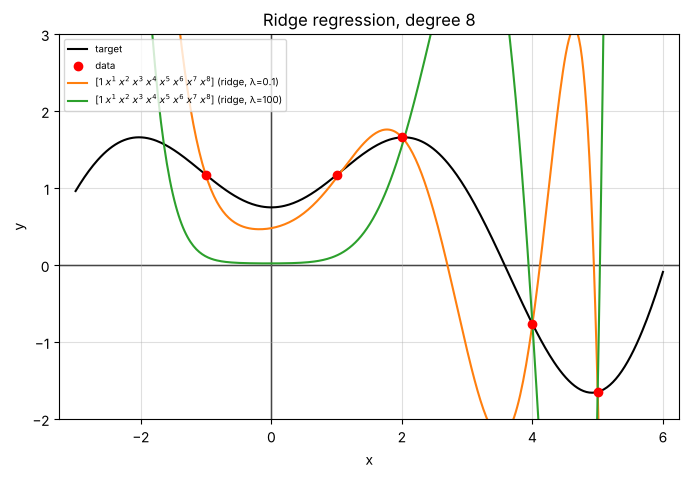

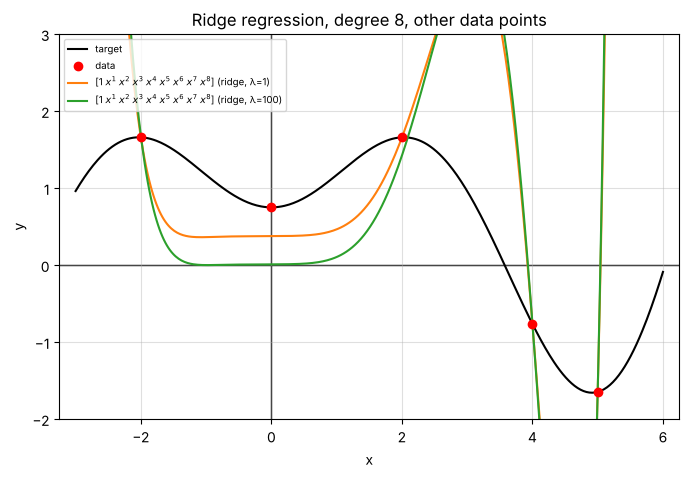

In [2]:
compare(np.array([-1, 1, 2, 4, 5]), f(np.array([-1, 1, 2, 4, 5])),
        [PolynomialRegression(range(9), lam=0.1), PolynomialRegression(range(9), lam=100)],
        "Ridge regression, degree 8")

compare(np.array([-2, 0, 2, 4, 5]), f(np.array([-2, 0, 2, 4, 5])),
        [PolynomialRegression(range(9), lam=1), PolynomialRegression(range(9), lam=100)],
        "Ridge regression, degree 8, other data points")

## Thirty noisy points

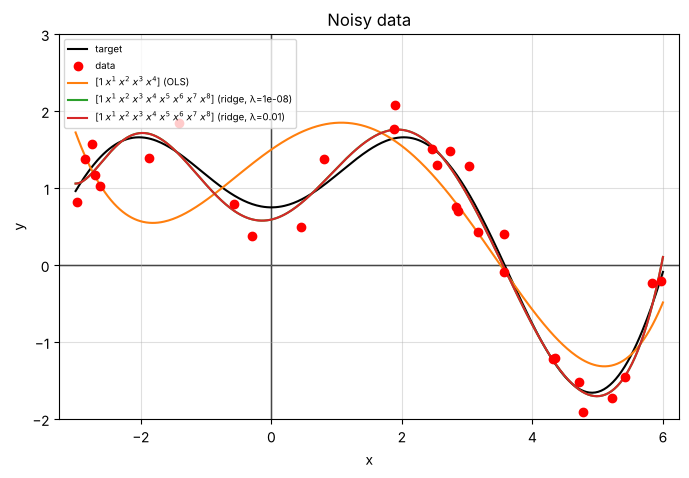

In [3]:
x_noisy = rng.uniform(-3, 6, 30)
y_noisy = f(x_noisy) + rng.uniform(-0.5, 0.5, 30)
compare(x_noisy, y_noisy,
        [PolynomialRegression(range(5)), PolynomialRegression(range(9), lam=1e-8),
         PolynomialRegression(range(9), lam=0.01)],
        "Noisy data")

With 30 points the problem is well determined: the two degree-8 fits lie on
top of each other and follow the target closely, so the regularisation
hardly matters any more. The degree-4 polynomial is too stiff to follow the
function.